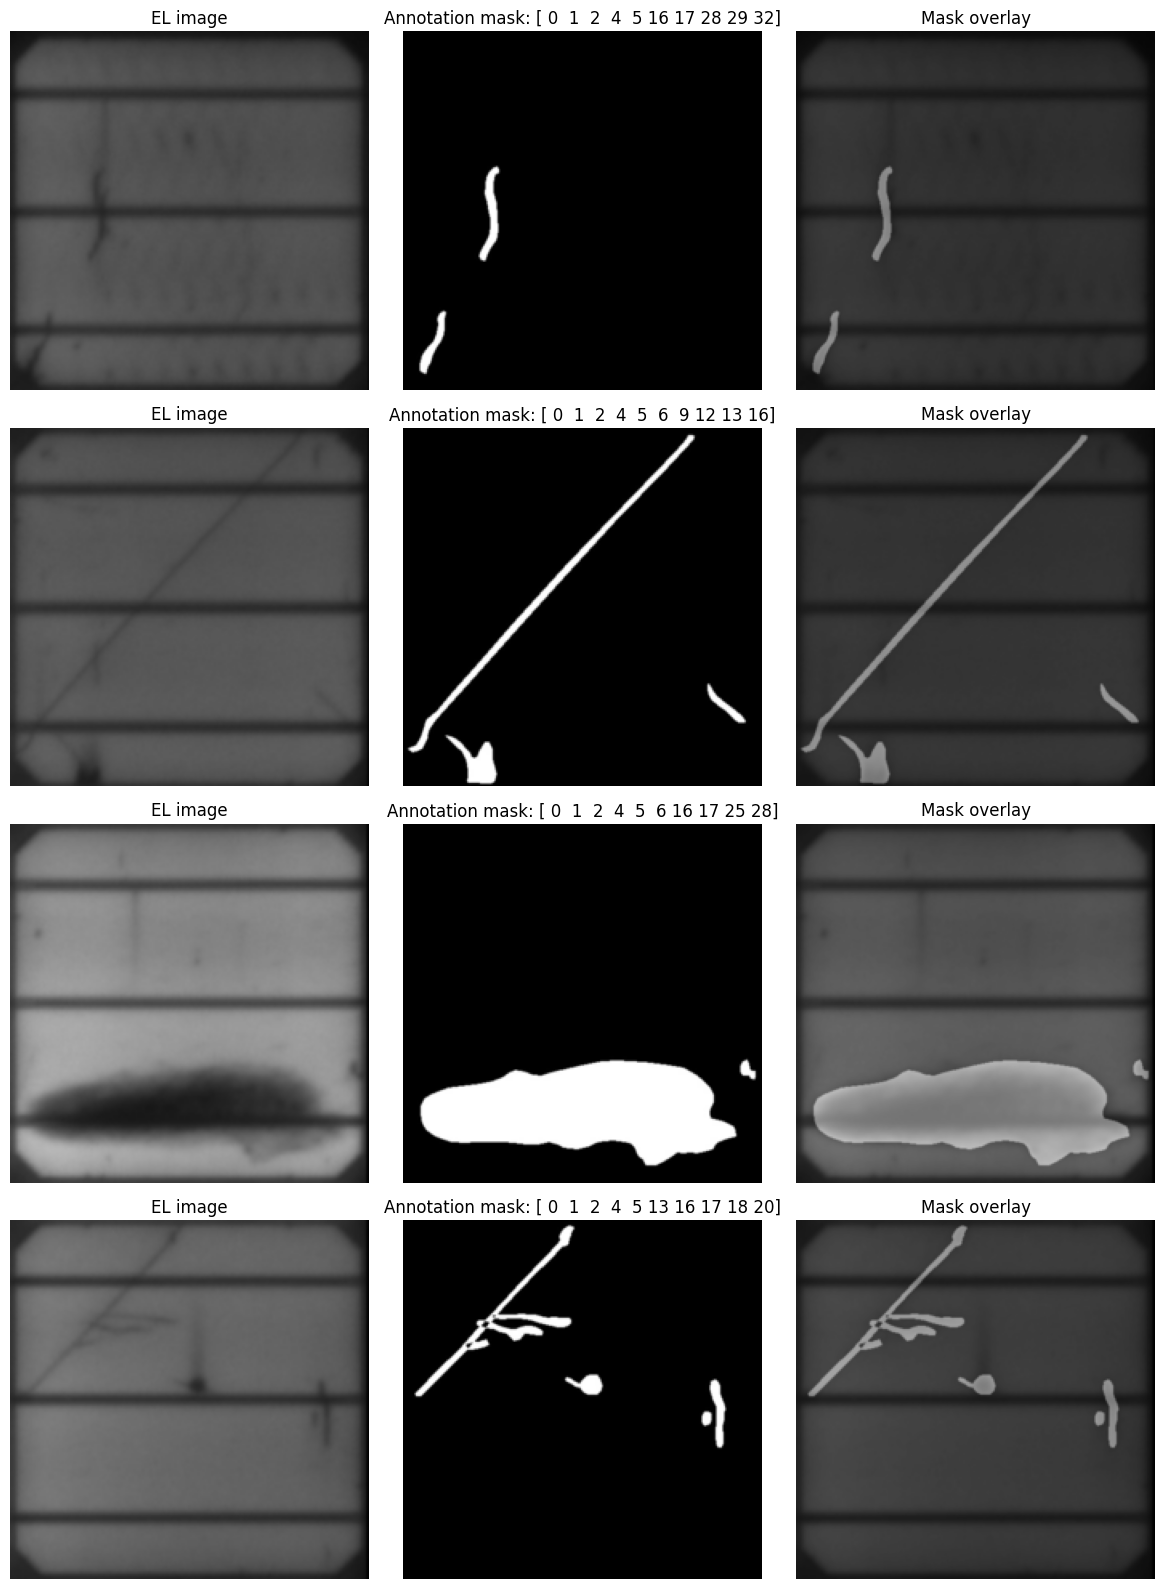

In [2]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "processed" / "SolarCells").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find data/processed/SolarCells from the notebook folder.")

root = project_root / "data" / "processed" / "SolarCells" / "train"
image_files = sorted((root / "defect").glob("*.png"))

if not image_files:
    raise RuntimeError(f"No processed training images found in {root / 'defect'}.")

missing_masks = [
    image_path.name for image_path in image_files
    if not (root / "label" / f"{image_path.stem}_mask.png").is_file()
]
if missing_masks:
    raise FileNotFoundError(f"Missing masks for: {', '.join(missing_masks[:10])}")

fig, axes = plt.subplots(
    min(4, len(image_files)), 3,
    figsize=(12, 4 * min(4, len(image_files))),
    squeeze=False
)

for row, image_path in enumerate(image_files[:4]):
    mask_path = root / "label" / f"{image_path.stem}_mask.png"

    with Image.open(image_path) as im:
        image = np.asarray(im.convert("RGB"))

    with Image.open(mask_path) as m:
        mask = np.asarray(m)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("EL image")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"Annotation mask: {np.unique(mask)[:10]}")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(mask, cmap="Reds", alpha=0.4)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from PIL import Image
import numpy as np
from pathlib import Path

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "SolarCells").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find data/SolarCells from the notebook folder.")

mask_path = project_root / "data" / "SolarCells" / "train" / "label"
mask_files = sorted(
    p for p in mask_path.rglob("*")
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)
if not mask_files:
    raise FileNotFoundError(f"No mask images found in {mask_path}.")

mask_file = mask_files[0]
mask = np.array(Image.open(mask_file).convert("L"))

print("Mask file:", mask_file.name)
print("Shape:", mask.shape)
print("Unique pixel values:", np.unique(mask))
print("Minimum:", mask.min())
print("Maximum:", mask.max())

Mask file: 000_mask.jpg
Shape: (448, 448)
Unique pixel values: [  0   1   2   3   4   5   6 248 249 250 251 252 253 254 255]
Minimum: 0
Maximum: 255


In [7]:
from PIL import Image
import numpy as np
def preprocess_mask(mask_path, output_path, size=(224, 224)):
    mask = Image.open(mask_path).convert("L")

    # Resize with nearest-neighbor interpolation
    mask = mask.resize(size, Image.Resampling.NEAREST)

    mask_array = np.array(mask)

    # Background = 0, defect = 1
    binary_mask = (mask_array > 127).astype(np.uint8)

    # Save as black and white for visual inspection
    Image.fromarray(binary_mask * 255).save(output_path)

    return binary_mask

In [13]:
output_path = project_root / "data" / "processed" / "SolarCells" / "train" / "binary_masks" / "test_binary_mask.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

processed_mask = preprocess_mask(
    mask_file,
    output_path,
)

print("Saved binary mask:", output_path)
print("Unique processed values:", np.unique(processed_mask))

Saved binary mask: d:\Machine_Learning\ML_Proj\data\processed\SolarCells\train\binary_masks\test_binary_mask.png
Unique processed values: [0 1]


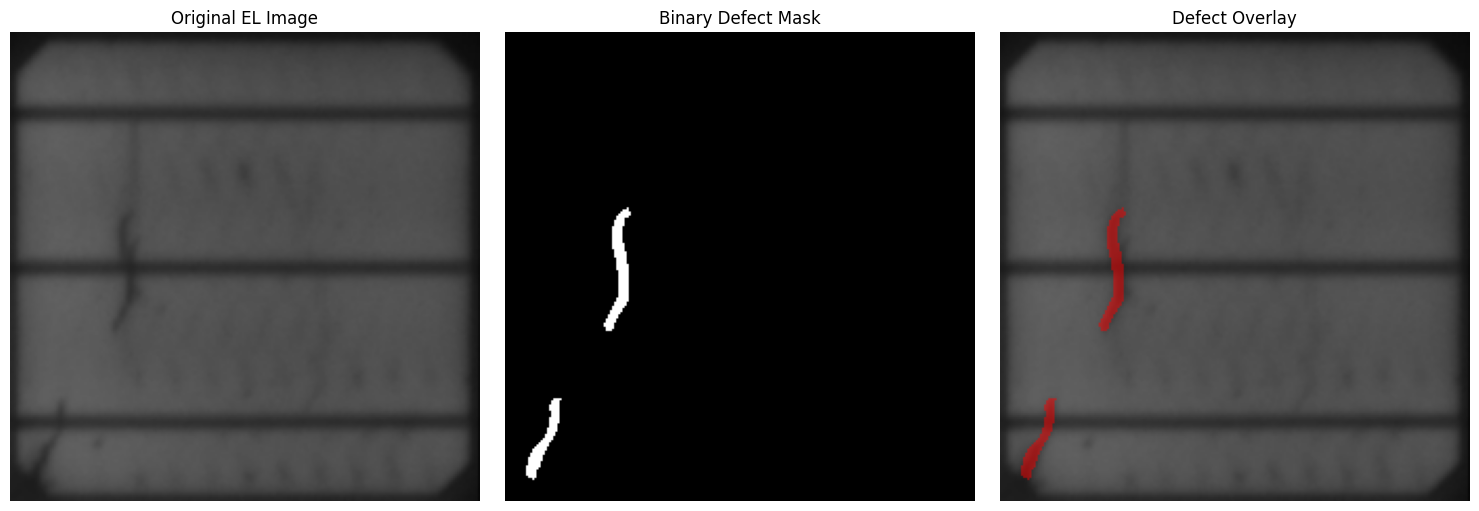

In [15]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

raw_image_dir = project_root / "data" / "SolarCells" / "train" / "defect"
image_stem = mask_file.stem.removesuffix("_mask")
image_candidates = sorted(
    path for path in raw_image_dir.glob(f"{image_stem}.*")
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
)
if not image_candidates:
    raise FileNotFoundError(f"No source image found for mask {mask_file.name} in {raw_image_dir}.")
image_path = image_candidates[0]

binary_mask_path = (
    project_root / "data" / "processed" / "SolarCells" / "train"
    / "binary_masks" / "test_binary_mask.png"
)
if not binary_mask_path.is_file():
    raise FileNotFoundError(f"Processed binary mask not found: {binary_mask_path}")

image = Image.open(image_path).convert("RGB")
mask = (
    np.array(Image.open(binary_mask_path).convert("L")) > 0
).astype(np.uint8)

image = image.resize((mask.shape[1], mask.shape[0]))
image_array = np.array(image)

overlay = image_array.copy()
overlay[mask == 1] = (
    0.5 * overlay[mask == 1] + 0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_array)
axes[0].set_title("Original EL Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Binary Defect Mask")

axes[2].imshow(overlay)
axes[2].set_title("Defect Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()